In [1]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt

print("Transportation dataset is ready")

Transportation dataset is ready


In [2]:
print(os.getcwd())

C:\Users\Hp\Desktop\Chicago_Weather-Transportation\notebooks


In [3]:
cd ..

C:\Users\Hp\Desktop\Chicago_Weather-Transportation


In [4]:
df= pd.read_csv("datasets/CTA_-_Ridership_-_Daily_Boarding_Totals_20260924.csv")
df.head(5)

,service_date,day_type,bus,rail_boardings,total_rides
0,01/01/2001,U,"297,192","126,455","423,647"
1,01/02/2001,W,"780,827","501,952","1,282,779"
2,01/03/2001,W,"824,923","536,432","1,361,355"
3,01/04/2001,W,"870,021","550,011","1,420,032"
4,01/05/2001,W,"890,426","557,917","1,448,343"


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9312 entries, 0 to 9311
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   service_date    9312 non-null   object
 1   day_type        9312 non-null   object
 2   bus             9312 non-null   object
 3   rail_boardings  9312 non-null   object
 4   total_rides     9312 non-null   object
dtypes: object(5)
memory usage: 363.9+ KB


In [6]:
df.columns

Index(['service_date', 'day_type', 'bus', 'rail_boardings', 'total_rides'], dtype='object')

In [7]:
df.isnull().sum()

service_date      0
day_type          0
bus               0
rail_boardings    0
total_rides       0
dtype: int64

In [8]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
9307    False
9308    False
9309    False
9310    False
9311    False
Length: 9312, dtype: bool

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.dtypes

service_date      object
day_type          object
bus               object
rail_boardings    object
total_rides       object
dtype: object

In [11]:
df.head(5)

,service_date,day_type,bus,rail_boardings,total_rides
0,01/01/2001,U,"297,192","126,455","423,647"
1,01/02/2001,W,"780,827","501,952","1,282,779"
2,01/03/2001,W,"824,923","536,432","1,361,355"
3,01/04/2001,W,"870,021","550,011","1,420,032"
4,01/05/2001,W,"890,426","557,917","1,448,343"


In [12]:
df["bus"]= df["bus"].str.replace(",", "")

In [13]:
df["bus"].dtype

dtype('O')

In [14]:
df["bus"]= df["bus"].astype(int)

In [15]:
df["bus"].dtype

dtype('int64')

In [16]:
df["rail_boardings"]= df["rail_boardings"].str.replace(",","")

In [17]:
df["rail_boardings"]= df["rail_boardings"].astype(int)

In [18]:
df["total_rides"]= df["total_rides"].str.replace(",","")
df["total_rides"]= df["total_rides"].astype(int)

In [19]:
df["total_rides"].dtype

dtype('int64')

In [20]:
df["rail_boardings"].dtype

dtype('int64')

In [21]:
df["service_date"]=pd.to_datetime(df["service_date"])

In [22]:
df["service_date"].dtype

dtype('<M8[ns]')

In [23]:
df.describe()

,service_date,bus,rail_boardings,total_rides
count,9312,9.312000e+03,9.312000e+03,9.312000e+03
mean,2013-09-30 12:00:00,7.023696e+05,5.035649e+05,1.205934e+06
min,2001-01-01 00:00:00,8.078300e+04,2.354400e+04,1.100470e+05
25%,2007-05-17 18:00:00,4.615280e+05,3.264688e+05,7.982322e+05
50%,2013-09-30 12:00:00,7.328475e+05,5.582580e+05,1.331625e+06
75%,2020-02-14 06:00:00,9.525740e+05,6.835025e+05,1.623327e+06
max,2026-06-30 00:00:00,1.211992e+06,1.146516e+06,2.049519e+06
std,NaN,2.670212e+05,2.057457e+05,4.599578e+05


<Axes: xlabel='bus', ylabel='Count'>

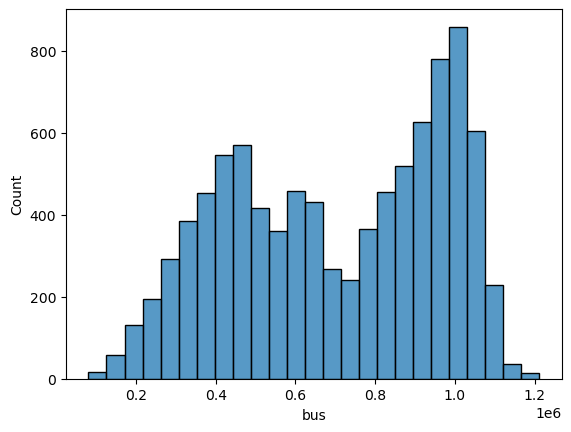

In [24]:
sns.histplot(data= df, x= "bus")

<Axes: xlabel='service_date', ylabel='bus'>

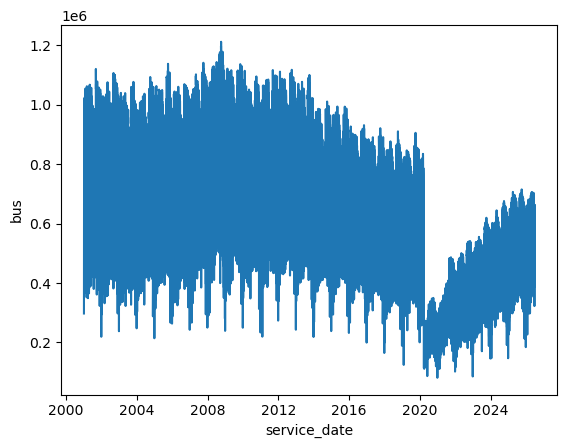

In [25]:
sns.lineplot(data= df, x="service_date", y="bus")

In [26]:
df_2020=df[df["service_date"] >= "2020-01-01"]

In [27]:
df_2020.head(5)

,service_date,day_type,bus,rail_boardings,total_rides
6939,2020-01-01,U,267300,255759,523059
6940,2020-01-02,W,651421,565139,1216560
6941,2020-01-03,W,688165,578202,1266367
6942,2020-01-04,A,409243,306656,715899
6943,2020-01-05,U,314424,234155,548579


In [28]:
df_2020.tail(5)

,service_date,day_type,bus,rail_boardings,total_rides
9307,2026-06-26,W,602267,432822,1035089
9308,2026-06-27,A,500926,381436,882362
9309,2026-06-28,U,393301,372432,765733
9310,2026-06-29,W,612746,422790,1035536
9311,2026-06-30,W,632314,459373,1091687


In [29]:
df_covid= df[(df["service_date"] <= "2021-12-31") & (df["service_date"] >= "2019-01-01")].copy()

In [30]:
df_covid.head(5)

,service_date,day_type,bus,rail_boardings,total_rides
6574,2019-01-01,U,248879,245852,494731
6575,2019-01-02,W,591006,573542,1164548
6576,2019-01-03,W,664442,627781,1292223
6577,2019-01-04,W,668812,628514,1297326
6578,2019-01-05,A,444434,348257,792691


In [31]:
df_covid.tail(5)

,service_date,day_type,bus,rail_boardings,total_rides
7665,2021-12-27,W,276748,170801,447549
7666,2021-12-28,W,267102,174336,441438
7667,2021-12-29,W,294413,191745,486158
7668,2021-12-30,W,295024,194851,489875
7669,2021-12-31,U,227449,163183,390632


In [32]:
df_covid["year"]= df_covid["service_date"].dt.year

In [33]:
df_covid.head(5)

,service_date,day_type,bus,rail_boardings,total_rides,year
6574,2019-01-01,U,248879,245852,494731,2019
6575,2019-01-02,W,591006,573542,1164548,2019
6576,2019-01-03,W,664442,627781,1292223,2019
6577,2019-01-04,W,668812,628514,1297326,2019
6578,2019-01-05,A,444434,348257,792691,2019


In [34]:
df_covid.groupby("year")["bus"].mean()

year
2019    650072.326027
2020    331830.382514
2021    321527.457534
Name: bus, dtype: float64

<Axes: >

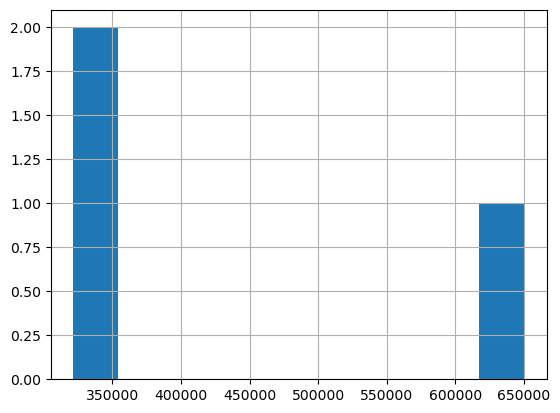

In [35]:
df_covid.groupby("year")["bus"].mean().hist()

<Axes: xlabel='service_date', ylabel='bus'>

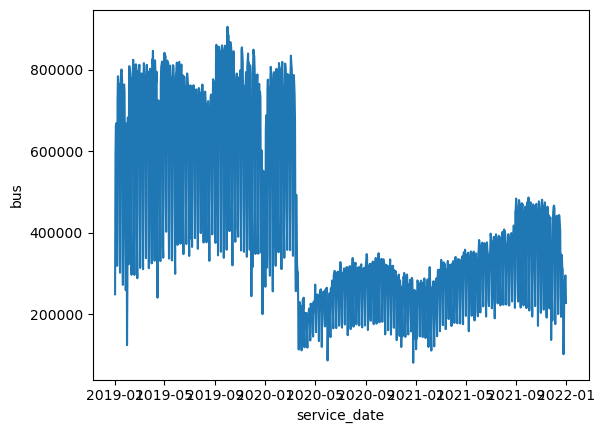

In [36]:
sns.lineplot(data = df_covid, x="service_date", y= "bus")

In [37]:
df_covid["month"] = df_covid["service_date"].dt.month

<Axes: xlabel='month', ylabel='bus'>

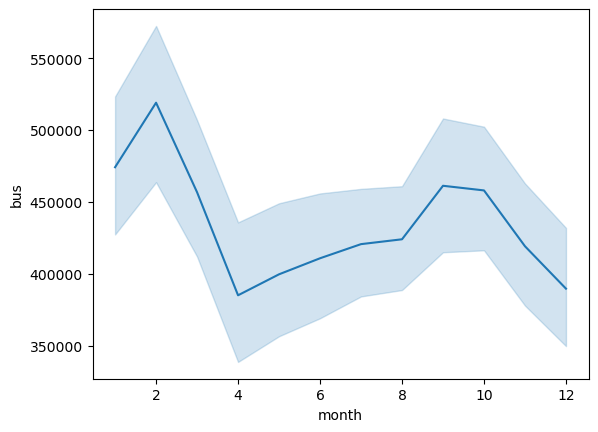

In [38]:
sns.lineplot(data = df_covid, x="month", y= "bus")

In [39]:
df_covid["month_year"]=df_covid["service_date"].dt.to_period("M") 


In [40]:
df_covid["month_year"]= df_covid["month_year"].astype(str)

In [41]:

df_covid["month_year"]=pd.to_datetime(df_covid["month_year"])

<Axes: xlabel='month_year', ylabel='bus'>

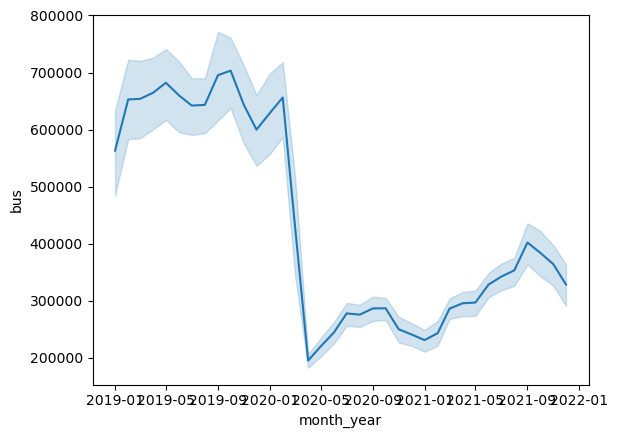

In [42]:

sns.lineplot(data = df_covid, x="month_year", y="bus")

In [43]:
df_covid["month_year_mean"]= df_covid.groupby("month_year")["bus"].mean()

In [44]:
monthly_bus = df_covid.groupby("month_year")["bus"].mean()

In [45]:
monthly_bus

month_year
2019-01-01    563028.000000
2019-02-01    652809.857143
2019-03-01    653778.935484
2019-04-01    664562.666667
2019-05-01    682092.516129
2019-06-01    659809.800000
2019-07-01    642061.838710
2019-08-01    643248.645161
2019-09-01    695255.966667
2019-10-01    703238.709677
2019-11-01    643480.266667
2019-12-01    599792.064516
2020-01-01    628464.096774
2020-02-01    656210.862069
2020-03-01    430343.741935
2020-04-01    195055.066667
2020-05-01    220091.903226
2020-06-01    244389.700000
2020-07-01    277691.193548
2020-08-01    275514.032258
2020-09-01    286440.466667
2020-10-01    286671.096774
2020-11-01    249798.066667
2020-12-01    240878.967742
2021-01-01    230863.935484
2021-02-01    243111.107143
2021-03-01    286049.967742
2021-04-01    295486.000000
2021-05-01    296700.838710
2021-06-01    328157.033333
2021-07-01    342101.096774
2021-08-01    353215.516129
2021-09-01    401958.833333
2021-10-01    384052.548387
2021-11-01    364130.866667
2021-12-0

In [46]:
monthly_bus= monthly_bus.reset_index()

In [47]:
monthly_bus.head(5)

,month_year,bus
0,2019-01-01,563028.000000
1,2019-02-01,652809.857143
2,2019-03-01,653778.935484
3,2019-04-01,664562.666667
4,2019-05-01,682092.516129


(array([17897., 18017., 18140., 18262., 18383., 18506., 18628., 18748.,
        18871., 18993.]),
 [Text(17897.0, 0, '2019-01'),
  Text(18017.0, 0, '2019-05'),
  Text(18140.0, 0, '2019-09'),
  Text(18262.0, 0, '2020-01'),
  Text(18383.0, 0, '2020-05'),
  Text(18506.0, 0, '2020-09'),
  Text(18628.0, 0, '2021-01'),
  Text(18748.0, 0, '2021-05'),
  Text(18871.0, 0, '2021-09'),
  Text(18993.0, 0, '2022-01')])

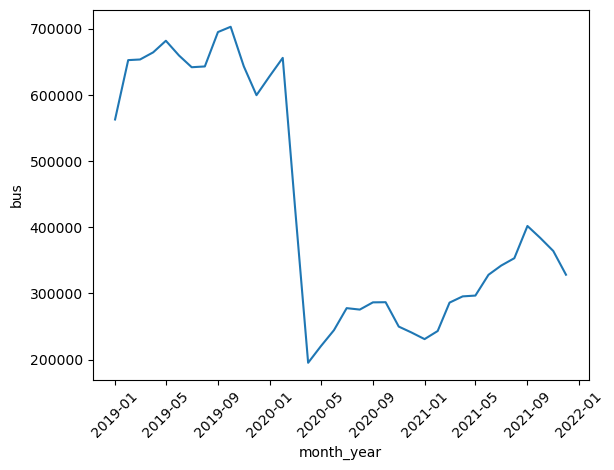

In [52]:
sns.lineplot( data= monthly_bus, x= "month_year", y= "bus")
plt.xticks(rotation= 45)